# 01 – Data Exploration
Size, labels, text and quality of the 47,837 Kaggle tickets; figures go to `figures/`.

In [1]:
import sys, json, re
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, LABELS, TEXT_COL, LABEL_COL, RESULTS_DIR
from src.plotting import set_style, save, SERIES, SERIES_MUTED, TEXT, TEXT_SECONDARY

set_style()
pd.set_option("display.max_colwidth", 160)
df = load_raw()
print(df.shape)
df.head()

(47837, 3)


,Document,Topic_group,n_words
0,connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead,Hardware,18
1,work experience user work experience user hi work experience student coming next his name much appreciate him duration thank,Access,19
2,requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug,Hardware,14
3,reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expirati...,Access,145
4,mail verification warning hi has got attached please addresses best regards monitoring analyst verification warning,Miscellaneous,15


## 1. Data quality checks

In [2]:
squash = df[TEXT_COL].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
quality = {
    "rows": len(df),
    "columns": list(df.columns[:2]),
    "missing_text": int(df[TEXT_COL].isna().sum()),
    "missing_label": int(df[LABEL_COL].isna().sum()),
    "exact_duplicate_texts": int(df[TEXT_COL].duplicated().sum()),
    "duplicates_after_whitespace_normalisation": int(squash.duplicated().sum()),
    "texts_with_conflicting_labels": int(df.groupby(TEXT_COL)[LABEL_COL].nunique().gt(1).sum()),
    "tickets_3_words_or_fewer": int((df.n_words <= 3).sum()),
    "vocabulary_size": len({w for t in df[TEXT_COL] for w in t.split()}),
}
quality

{'rows': 47837,
 'columns': ['Document', 'Topic_group'],
 'missing_text': 0,
 'missing_label': 0,
 'exact_duplicate_texts': 0,
 'duplicates_after_whitespace_normalisation': 0,
 'texts_with_conflicting_labels': 0,
 'tickets_3_words_or_fewer': 49,
 'vocabulary_size': 12327}

## 2. Class distribution
Imbalanced (~8:1), so we report per-class F1, not just accuracy.

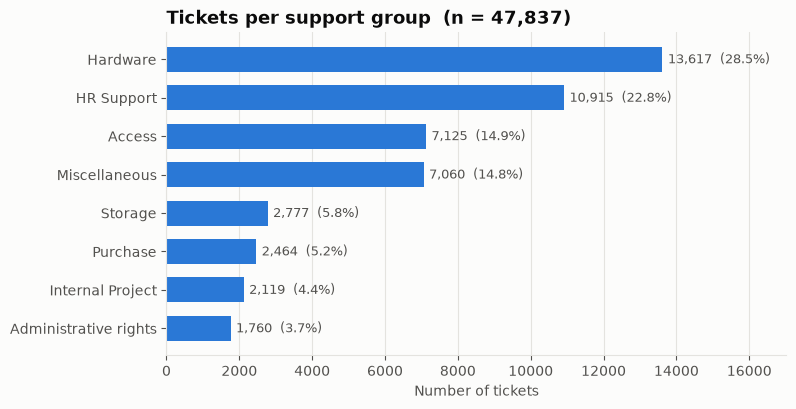

,tickets,percent
Topic_group,,
Hardware,13617,28.5
HR Support,10915,22.8
Access,7125,14.9
Miscellaneous,7060,14.8
Storage,2777,5.8
Purchase,2464,5.2
Internal Project,2119,4.4
Administrative rights,1760,3.7


In [3]:
counts = df[LABEL_COL].value_counts().reindex(LABELS)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(counts.index[::-1], counts.values[::-1], color=SERIES, height=0.65)
for y, (c, p) in enumerate(zip(counts.values[::-1], pct.values[::-1])):
    ax.text(c + 150, y, f"{c:,}  ({p:.1f}%)", va="center", color=TEXT_SECONDARY, fontsize=9)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of tickets")
ax.grid(axis="y", visible=False)
ax.set_title(f"Tickets per support group  (n = {len(df):,})")
save(fig, "01_class_distribution")
plt.show()
counts.to_frame("tickets").assign(percent=pct.round(1))

## 3. Ticket length
Median ~26 words with a long tail of email threads.

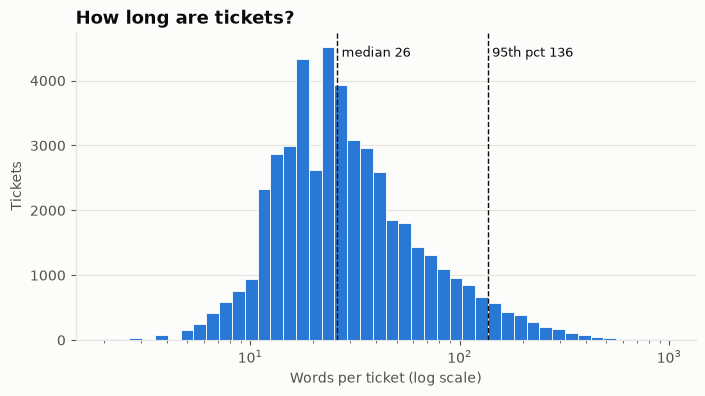

count    47837.0
mean        43.6
std         56.7
min          2.0
10%         12.0
50%         26.0
90%         91.0
95%        136.0
99%        284.0
max        981.0
Name: n_words, dtype: float64

In [4]:
med, p95 = df.n_words.median(), df.n_words.quantile(0.95)
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(2), np.log10(df.n_words.max()), 45)
ax.hist(df.n_words, bins=bins, color=SERIES, edgecolor="white", linewidth=0.6)
ax.set_xscale("log")
for v, lab in [(med, f"median {med:.0f}"), (p95, f"95th pct {p95:.0f}")]:
    ax.axvline(v, color=TEXT, linewidth=1, linestyle="--")
    ax.text(v * 1.05, ax.get_ylim()[1] * 0.92, lab, color=TEXT, fontsize=9)
ax.set_xlabel("Words per ticket (log scale)")
ax.set_ylabel("Tickets")
ax.grid(axis="x", visible=False)
ax.set_title("How long are tickets?")
save(fig, "02_ticket_length_hist")
plt.show()
df.n_words.describe(percentiles=[.1, .5, .9, .95, .99]).round(1)

/var/folders/x5/g42_klh17ksf2s5gq_3kjjf40000gp/T/ipykernel_24144/1171178158.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, showfliers=False, widths=0.55, patch_artist=True,


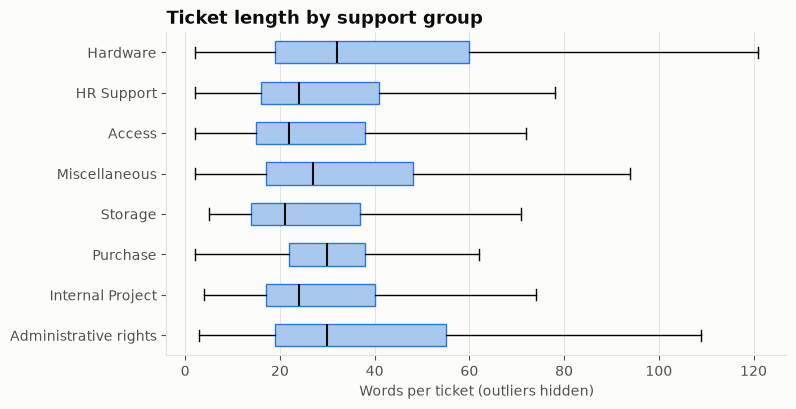

Topic_group
Hardware                 32.0
HR Support               24.0
Access                   22.0
Miscellaneous            27.0
Storage                  21.0
Purchase                 30.0
Internal Project         24.0
Administrative rights    30.0
Name: n_words, dtype: float64

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
data = [df.loc[df[LABEL_COL] == l, "n_words"] for l in LABELS[::-1]]
bp = ax.boxplot(data, vert=False, showfliers=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=TEXT, linewidth=1.5))
for b in bp["boxes"]:
    b.set(facecolor=SERIES_MUTED, edgecolor=SERIES)
ax.set_yticks(range(1, len(LABELS) + 1), LABELS[::-1])
ax.set_xlabel("Words per ticket (outliers hidden)")
ax.grid(axis="y", visible=False)
ax.set_title("Ticket length by support group")
save(fig, "03_ticket_length_by_class")
plt.show()
df.groupby(LABEL_COL).n_words.median().reindex(LABELS)

## 4. Most common words
Politeness words dominate and carry little signal.

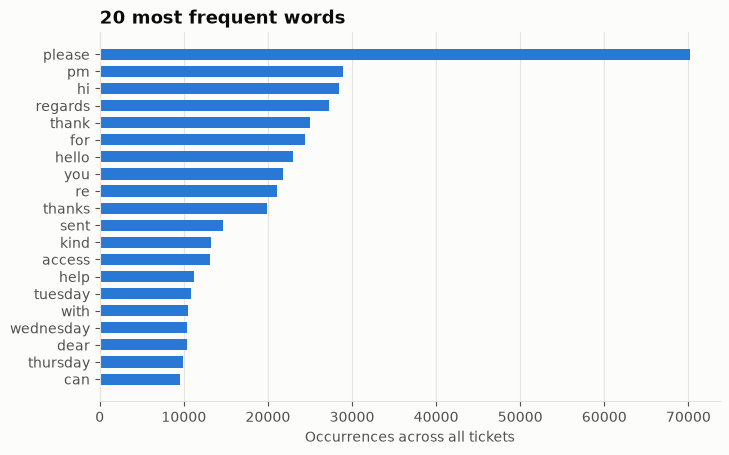

In [6]:
word_counts = Counter(w for t in df[TEXT_COL] for w in t.split())
top = pd.Series(dict(word_counts.most_common(20)))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index[::-1], top.values[::-1], color=SERIES, height=0.65)
ax.set_xlabel("Occurrences across all tickets")
ax.grid(axis="y", visible=False)
ax.set_title("20 most frequent words")
save(fig, "04_top_words_overall")
plt.show()

## 5. Distinctive words per group
Words far more frequent in one group than the others (≥ 3% of the group's tickets).

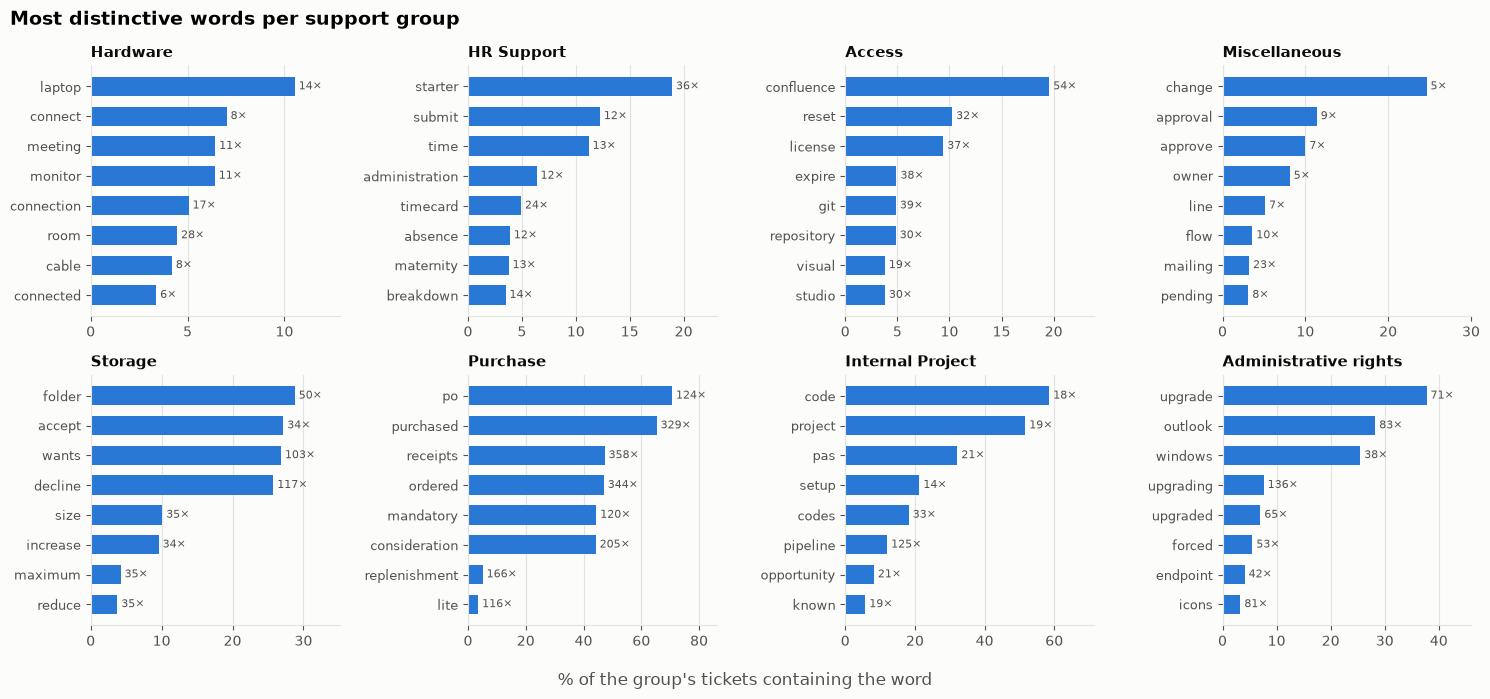

In [7]:
docs_by_class = {l: Counter(w for t in df.loc[df[LABEL_COL] == l, TEXT_COL] for w in set(t.split())) for l in LABELS}
n_by_class = df[LABEL_COL].value_counts()
total_df = Counter()
for c in docs_by_class.values():
    total_df.update(c)

def distinctive(label, k=8, min_share=0.03):
    n_in, n_out = n_by_class[label], len(df) - n_by_class[label]
    rows = []
    for w, c_in in docs_by_class[label].items():
        if c_in / n_in < min_share:
            continue
        c_out = total_df[w] - c_in
        ratio = ((c_in + 1) / (n_in + 2)) / ((c_out + 1) / (n_out + 2))
        rows.append((w, ratio, c_in / n_in))
    return pd.DataFrame(rows, columns=["word", "ratio", "share_in_class"]).nlargest(k, "ratio")

distinct = {l: distinctive(l) for l in LABELS}
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, l in zip(axes.flat, LABELS):
    d = distinct[l].sort_values("share_in_class")
    ax.barh(d.word, d.share_in_class * 100, color=SERIES, height=0.65)
    for y, (s, r) in enumerate(zip(d.share_in_class * 100, d.ratio)):
        ax.text(s, y, f" {r:.0f}×", va="center", fontsize=8, color=TEXT_SECONDARY)
    ax.set_xlim(0, d.share_in_class.max() * 100 * 1.22)
    ax.set_title(l, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
fig.supxlabel("% of the group's tickets containing the word", color=TEXT_SECONDARY)
fig.suptitle("Most distinctive words per support group", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "05_distinctive_words_by_class")
plt.show()

## 6. Example tickets
Text is already lowercased, punctuation and most stop words removed by the dataset author.

In [8]:
examples = (df[df.n_words.between(8, 40)]
              .groupby(LABEL_COL).sample(3, random_state=7)
              .sort_values(LABEL_COL, key=lambda s: s.map(LABELS.index))[[LABEL_COL, TEXT_COL]])
examples.to_csv(RESULTS_DIR / "example_tickets.csv", index=False)
examples

,Topic_group,Document
35922,Hardware,for for hi stopped working seem connect restarted machine but still same message still contacting server signing fusion
34782,Hardware,work without activation key re almost there machine your input needed hi kind reminder for issue below cannot perform some their work without having working...
29311,Hardware,changed from internal network to a dedicated tuesday pm changed dedicated hello after review discussion conclude moved dedicated please consider high priori...
14544,HR Support,new starter tower starter discipline dear please informed starter discipline engineer please create his credentials per attached form thank specialist
442,HR Support,close access to secured area et to close secured area dear please close secured area tower colleague rotating thank regards officer
8494,HR Support,reminder for leaver reminder leaver dear please help rid keeps coming everyday thanks friday reminder leaver dear please submit leaver form found messages r...
19635,Access,access rights for to confluence tuesday march rights confluence hi please confluence these needed thank
38211,Access,ad account locked for solved ad locked for solved hello please open ticket his ad was locked approached we were able assist him by unlocking his thank you e...
20926,Access,new needed tuesday february pm needed hello users added please let additional kind regards consultant
27333,Miscellaneous,permission to send to all staff and to all staff friday october pm add shared mailbox hello regarding ask please permission members thank much best regards ...


## 7. Label conventions
Routing follows the company's own rules (e.g. Outlook → Administrative rights); some keywords are split across groups.

In [9]:
rows = []
for kw in ["outlook", "password", "restricted area", "laptop", "folder"]:
    sub = df[df[TEXT_COL].str.contains(rf"\b{kw}\b", regex=True)]
    dist = sub[LABEL_COL].value_counts(normalize=True).mul(100).round(1)
    rows.append({"keyword": kw, "tickets": len(sub), **dist.to_dict()})
noise = pd.DataFrame(rows).set_index("keyword").reindex(columns=["tickets"] + LABELS).fillna(0)
noise

,tickets,Hardware,HR Support,Access,Miscellaneous,Storage,Purchase,Internal Project,Administrative rights
keyword,,,,,,,,,
outlook,653,7.5,1.2,1.2,4.7,8.7,0.5,0.0,76.1
password,1646,19.9,0.5,70.8,0.6,1.0,0.2,0.0,7.0
restricted area,13,0.0,69.2,30.8,0.0,0.0,0.0,0.0,0.0
laptop,1685,85.1,1.2,4.3,0.9,0.4,0.9,0.1,7.1
folder,1059,14.5,1.0,4.1,2.0,75.4,0.1,0.2,2.6


## 8. Save summary

In [10]:
summary = {**quality,
           "class_counts": counts.to_dict(),
           "imbalance_ratio_largest_to_smallest": round(float(counts.max() / counts.min()), 2),
           "words_median": float(df.n_words.median()),
           "words_p95": float(df.n_words.quantile(0.95)),
           "words_max": int(df.n_words.max())}
RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "data_summary.json").write_text(json.dumps(summary, indent=2))
summary

{'rows': 47837,
 'columns': ['Document', 'Topic_group'],
 'missing_text': 0,
 'missing_label': 0,
 'exact_duplicate_texts': 0,
 'duplicates_after_whitespace_normalisation': 0,
 'texts_with_conflicting_labels': 0,
 'tickets_3_words_or_fewer': 49,
 'vocabulary_size': 12327,
 'class_counts': {'Hardware': 13617,
  'HR Support': 10915,
  'Access': 7125,
  'Miscellaneous': 7060,
  'Storage': 2777,
  'Purchase': 2464,
  'Internal Project': 2119,
  'Administrative rights': 1760},
 'imbalance_ratio_largest_to_smallest': 7.74,
 'words_median': 26.0,
 'words_p95': 136.0,
 'words_max': 981}